# Online Retail Sales Analysis

**Module:** Data Visualisation and Communication

**Assessment:** CA2

**Student Name:** Jefferson Arcanjo

**Student Number:** 2023240

**Institution:** CCT College Dublin

 ## 1 - Introduction

This project explores an online retail dataset containing
transactional data from a gift wholesaler.

The company has experienced growth but has not systematically
analysed its sales data. As a result, managers have limited
visibility of product performance, customer behaviour,
regional sales and revenue trends.

The purpose of this analysis is to clean, explore and visualise
the dataset to identify meaningful patterns and provide useful
insights that can support business decisions.

An interactive dashboard will also be developed to allow
managers to explore sales performance using different filters.

###  Business Objectives

The analysis aims to answer the following business questions:

1. How does revenue change over time?
2. Which products generate the highest revenue?
3. Which countries contribute the most to total sales?
4. What is the distribution of customer order values?
5. How does purchasing behaviour vary between customers?
6. Which days and hours experience the highest sales activity?

These questions will guide the exploratory data analysis
and the development of the interactive dashboard.

### Project Methodology

The project is divided into the following stages:

1. Data import and initial exploration.
2. Data quality assessment.
3. Data cleaning and preparation.
4. Feature engineering.
5. Descriptive statistics.
6. Exploratory data analysis and static visualisations.
7. Interactive dashboard development.
8. Business recommendations and limitations.

Python and Jupyter Notebook will be used throughout the
project to combine code, visualisations and written
explanation.

## 2 - Data Import and Initial Exploration

Before cleaning and analysing the dataset, it is important
to understand its structure and the type of information it
contains.

This section focuses on loading the original dataset,
examining its dimensions, identifying the available variables
and checking their data types.

This initial exploration will help identify potential data
quality issues and guide the cleaning process.

In [1]:
# Import the libraries needed for the analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the original dataset

retail_data = pd.read_excel("../data/Online Retail.xlsx")

# Display the first five records

retail_data.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
#  Check the dataset dimensions

print("Number of rows:", retail_data.shape[0])
print("Number of columns:", retail_data.shape[1])

# Display the column names

print("\nColumn names:")
print(retail_data.columns.tolist())

Number of rows: 541909
Number of columns: 8

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [4]:
# Check data types and dataset structure

retail_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


### Variable Description

| Variable | Description |
|---|---|
| InvoiceNo | Order identifier |
| StockCode | Product identifier |
| Description | Product description |
| Quantity | Number of units purchased |
| InvoiceDate | Transaction date and time |
| UnitPrice | Price per unit |
| CustomerID | Customer identifier |
| Country | Customer's country |

Each row represents a transaction line rather than a
complete order, as an invoice can contain multiple products.

### Initial Observations

The dataset contains 541,909 transaction lines and eight
variables, covering product details, quantities, prices,
customer information and countries.

The first five records share the same invoice number,
confirming that an order can contain multiple products.

The initial inspection shows missing values in Description
and CustomerID. InvoiceDate is already stored in datetime
format, while Quantity and UnitPrice are numerical.

These findings will guide the next stage of the data
quality assessment.

## 3 Data Quality Assessment

Before cleaning the dataset, missing values and duplicate
records are examined to understand their impact on data
quality and the reliability of the analysis.

In [5]:
#  Count missing values in each column

missing_values = retail_data.isna().sum()

print(missing_values)

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [6]:
#  Calculate the percentage of missing values

missing_percentage = (missing_values / len(retail_data)) * 100

# Create a summary table

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage (%)": missing_percentage.round(2)
})

missing_summary

,Missing Values,Percentage (%)
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


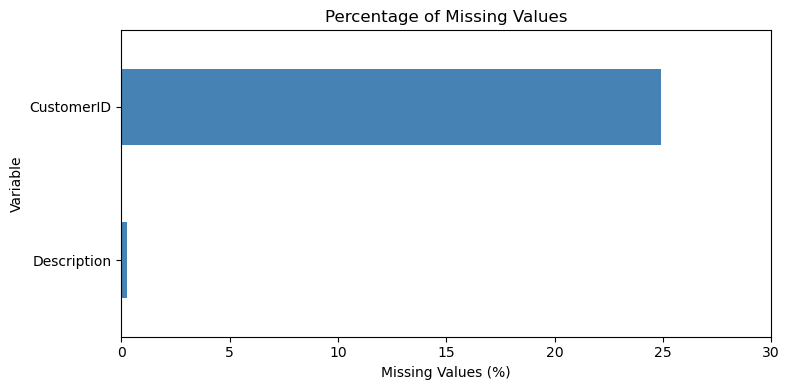

In [7]:
#  Visualise columns with missing values

missing_columns = missing_percentage[missing_percentage > 0]

plt.figure(figsize=(8, 4))

missing_columns.plot(kind="barh", color="steelblue")

plt.title("Percentage of Missing Values")
plt.xlabel("Missing Values (%)")
plt.ylabel("Variable")
plt.xlim(0, 30)

plt.tight_layout()
plt.show()

### Missing Values

CustomerID has the highest proportion of missing values
(24.93%), followed by Description (0.27%).

A horizontal bar chart was selected to make the difference
between the two variables easy to compare.

Missing customer IDs may limit customer behaviour analysis.
However, these records may still contain useful sales
information, so removing them immediately could result
in unnecessary data loss.

In [8]:
# Count duplicate records

duplicate_count = retail_data.duplicated().sum()

duplicate_percentage = (duplicate_count / len(retail_data)) * 100

print("Number of duplicate records:", duplicate_count)
print("Percentage of duplicates:", round(duplicate_percentage, 2), "%")

Number of duplicate records: 5268
Percentage of duplicates: 0.97 %


In [9]:
# Display examples of duplicate records
retail_data[retail_data.duplicated(keep=False)].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


### Duplicate Records

The dataset contains 5,268 additional duplicate records,
representing 0.97% of the original data.

Identical records were examined across all eight variables.
If these records are duplicated in error, they could lead
to an overestimation of sales quantities and revenue.

However, some identical records may represent legitimate
repeated purchases. This limitation will be considered
during the cleaning process.

## 4. Invalid Transactions and Outlier Assessment
This section investigates cancelled transactions, invalid
quantities, unit prices and potential outliers. These
records may distort revenue calculations and affect the
reliability of the business analysis.

In [10]:
# Identify cancelled transaction lines

cancelled_mask = retail_data["InvoiceNo"].astype(str).str.startswith("C")

cancelled_transactions = retail_data[cancelled_mask]

# Calculate cancellation statistics

cancelled_count = len(cancelled_transactions)

cancelled_percentage = (cancelled_count / len(retail_data)) * 100

print("Cancelled transaction lines:", cancelled_count)
print("Percentage:", round(cancelled_percentage, 2), "%")
print("Unique cancelled invoices:", cancelled_transactions["InvoiceNo"].nunique())

# Display examples of cancelled transactions

cancelled_transactions.head()

Cancelled transaction lines: 9288
Percentage: 1.71 %
Unique cancelled invoices: 3836


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [11]:
# Count negative and zero quantities

negative_quantity = (retail_data["Quantity"] < 0).sum()
zero_quantity = (retail_data["Quantity"] == 0).sum()

# Count negative and zero unit prices

negative_price = (retail_data["UnitPrice"] < 0).sum()
zero_price = (retail_data["UnitPrice"] == 0).sum()

# Create a summary table

invalid_summary = pd.DataFrame({
    "Data Quality Issue": [
        "Negative Quantity",
        "Zero Quantity",
        "Negative Unit Price",
        "Zero Unit Price"
    ],
    "Number of Records": [
        negative_quantity,
        zero_quantity,
        negative_price,
        zero_price
    ]
})

# Calculate percentages

invalid_summary["Percentage (%)"] = (
    invalid_summary["Number of Records"] / len(retail_data) * 100
).round(2)

invalid_summary

,Data Quality Issue,Number of Records,Percentage (%)
0,Negative Quantity,10624,1.96
1,Zero Quantity,0,0.00
2,Negative Unit Price,2,0.00
3,Zero Unit Price,2515,0.46


In [12]:
# Identify negative quantities outside cancelled invoices

negative_non_cancelled = retail_data[
    (retail_data["Quantity"] < 0) &
    (~cancelled_mask)
]

print("Negative quantities in non-cancelled invoices:",
      len(negative_non_cancelled))

negative_non_cancelled.head(10)

Negative quantities in non-cancelled invoices: 1336


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom


### Invalid Transaction Findings

The dataset contains 9,288 cancelled transaction lines, 
representing 1.71% of all records. However, 1,336 negative 
quantity records were identified outside cancelled invoices, 
showing that invoice prefixes alone are insufficient for 
identifying invalid sales.

Several of these records contain zero prices and missing 
customer information, suggesting possible stock adjustments 
rather than completed sales.

Additionally, 2,515 zero-priced records and two negative 
unit prices were identified. These records require separate 
consideration to avoid misleading revenue calculations.

### Statistical Outlier Assessment

The Interquartile Range (IQR) method is used to identify
unusually high or low quantities and unit prices.

As the company operates as a wholesaler, large purchases
may represent legitimate transactions rather than data
entry errors. Therefore, statistical outliers require
further investigation before removal.

In [13]:
# Select non-cancelled transactions with positive quantities and prices

valid_sales = retail_data[
    (~cancelled_mask) &
    (retail_data["Quantity"] > 0) &
    (retail_data["UnitPrice"] > 0)
].copy()

# Display descriptive statistics

valid_sales[["Quantity", "UnitPrice"]].describe().round(2)

,Quantity,UnitPrice
count,530104.00,530104.00
mean,10.54,3.91
std,155.52,35.92
min,1.00,0.00
25%,1.00,1.25
50%,3.00,2.08
75%,10.00,4.13
max,80995.00,13541.33


In [14]:
# Calculate the first and third quartiles

Q1 = valid_sales[["Quantity", "UnitPrice"]].quantile(0.25)
Q3 = valid_sales[["Quantity", "UnitPrice"]].quantile(0.75)

# Calculate the interquartile range

IQR = Q3 - Q1

# Calculate the outlier boundaries

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

# Identify potential outliers

outlier_mask = (
    (valid_sales[["Quantity", "UnitPrice"]] < lower_bound) |
    (valid_sales[["Quantity", "UnitPrice"]] > upper_bound)
)

# Create an outlier summary table

outlier_summary = pd.DataFrame({
    "Q1": Q1,
    "Q3": Q3,
    "IQR": IQR,
    "Lower Bound": lower_bound,
    "Upper Bound": upper_bound,
    "Outlier Count": outlier_mask.sum()
})

outlier_summary["Percentage (%)"] = (
    outlier_summary["Outlier Count"] / len(valid_sales) * 100
)

outlier_summary.round(2)

,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Percentage (%)
Quantity,1.00,10.00,9.00,-12.50,23.50,56363,10.63
UnitPrice,1.25,4.13,2.88,-3.07,8.45,37999,7.17


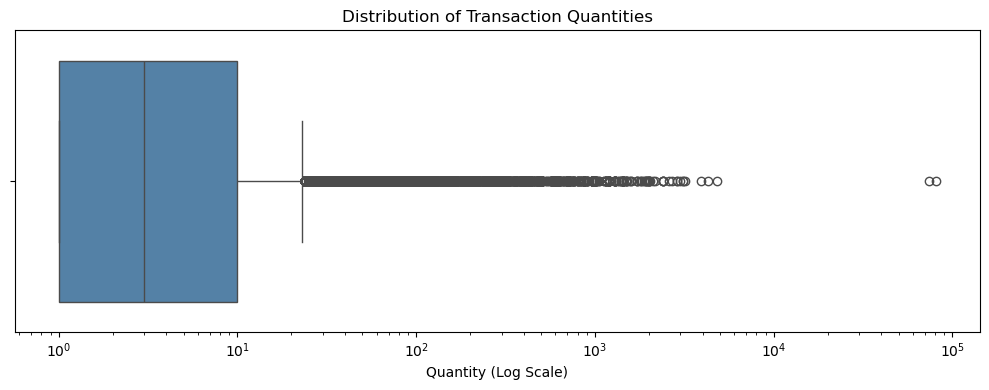

In [15]:
# Visualise the quantity distribution

plt.figure(figsize=(10, 4))

sns.boxplot(
    x=valid_sales["Quantity"],
    color="steelblue"
)

# Use a logarithmic scale to improve readability

plt.xscale("log")

plt.title("Distribution of Transaction Quantities")
plt.xlabel("Quantity (Log Scale)")

plt.tight_layout()
plt.show()

The quantity distribution is positively skewed, with a mean 
of 10.54 units compared to a median of 3 units. The middle 
50% of observations range from 1 to 10 units.

The IQR method identified 56,363 potential outliers (10.63%). 
However, large quantities may reflect legitimate wholesale 
purchases rather than recording errors.

A box plot was selected because it clearly displays the 
median, quartiles and extreme observations. A logarithmic 
scale improves readability without removing large values.

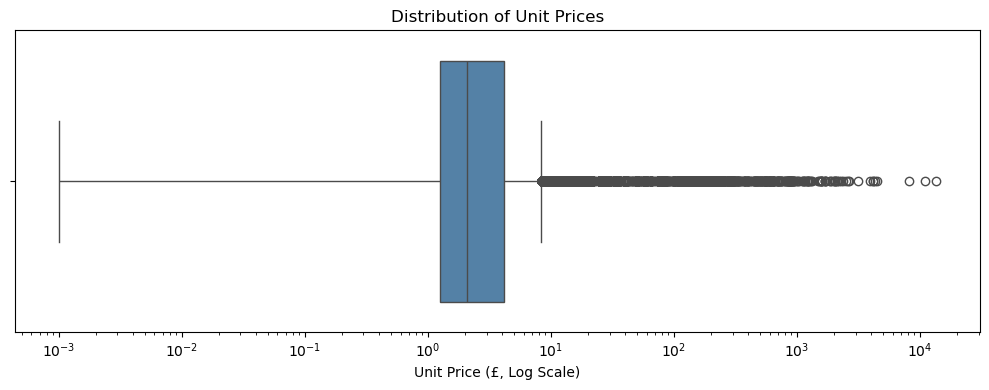

In [16]:
# Visualise the unit price distribution

plt.figure(figsize=(10, 4))

sns.boxplot(
    x=valid_sales["UnitPrice"],
    color="steelblue"
)

# Use a logarithmic scale to improve readability

plt.xscale("log")

plt.title("Distribution of Unit Prices")
plt.xlabel("Unit Price (£, Log Scale)")

plt.tight_layout()
plt.show()

The unit price distribution is also positively skewed, 
with a median of £2.08 and a mean of £3.91. The IQR method 
identified 37,999 potential outliers, representing 7.17% 
of the selected records.

The difference between the mean and median indicates 
that unusually expensive records influence the average. 
Therefore, the median provides a more representative 
measure of a typical unit price.

The box plot and logarithmic scale allow both typical 
prices and extreme observations to remain visible.

In [17]:
# Display transactions with the highest quantities

valid_sales.nlargest(10, "Quantity")[
    ["InvoiceNo", "Description", "Quantity", "UnitPrice", "Country"]
]

,InvoiceNo,Description,Quantity,UnitPrice,Country
540421,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,United Kingdom
61619,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,United Kingdom
421632,573008,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,United Kingdom
206121,554868,SMALL POPCORN HOLDER,4300,0.72,United Kingdom
97432,544612,EMPIRE DESIGN ROSETTE,3906,0.82,United Kingdom
270885,560599,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,United Kingdom
52711,540815,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,United Kingdom
160546,550461,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,United Kingdom
433788,573995,SMALL CHINESE STYLE SCISSOR,3000,0.32,United Kingdom
4945,536830,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2880,0.18,United Kingdom


In [18]:
# Display transactions with the highest unit prices

valid_sales.nlargest(10, "UnitPrice")[
    ["InvoiceNo", "Description", "Quantity", "UnitPrice", "Country"]
]

,InvoiceNo,Description,Quantity,UnitPrice,Country
15017,537632,AMAZON FEE,1,13541.33,United Kingdom
299982,A563185,Adjust bad debt,1,11062.06,United Kingdom
173382,551697,POSTAGE,1,8142.75,United Kingdom
297723,562955,DOTCOM POSTAGE,1,4505.17,United Kingdom
268028,560373,Manual,1,4287.63,United Kingdom
422351,573077,Manual,1,4161.06,France
422376,573080,Manual,1,4161.06,France
406406,571751,Manual,1,3949.32,Singapore
374542,569382,Manual,1,3155.95,United Kingdom
347948,567353,Manual,1,2653.95,Hong Kong


In [ ]:
### Investigation of Extreme Observations

The highest recorded quantities include 80,995 units of 
PAPER CRAFT, LITTLE BIRDIE and 74,215 units of MEDIUM 
CERAMIC TOP STORAGE JAR.

However, the highest unit prices include Amazon fees, 
bad debt adjustments, postage and manual entries rather 
than identifiable merchandise.

This demonstrates that positive quantities and prices 
alone are insufficient for identifying genuine product 
sales. Non-merchandise records require further investigation 
to prevent distortion of product performance and revenue 
analysis.

In [19]:
# Calculate transaction line values without changing the original data

transaction_value = retail_data["Quantity"] * retail_data["UnitPrice"]

# Calculate the value associated with cancelled transactions

cancelled_value = transaction_value[cancelled_mask].sum()

# Calculate positive sales value

valid_sales_value = valid_sales["Quantity"] * valid_sales["UnitPrice"]

total_sales_value = valid_sales_value.sum()

# Calculate sales value associated with missing customer IDs

missing_customer_value = valid_sales_value[
    valid_sales["CustomerID"].isna()
].sum()

missing_customer_percentage = (
    missing_customer_value / total_sales_value
) * 100

# Estimate the value of additional duplicate sales records

duplicate_value = valid_sales_value[
    valid_sales.duplicated()
].sum()

# Calculate the sales value associated with potential outliers

outlier_value = valid_sales_value[
    outlier_mask.any(axis=1)
].sum()

outlier_value_percentage = (
    outlier_value / total_sales_value
) * 100

# Display financial impact results

print(f"Cancelled transaction value: £{cancelled_value:,.2f}")

print(f"Positive sales value: £{total_sales_value:,.2f}")

print(f"Sales without customer IDs: £{missing_customer_value:,.2f}")

print(f"Percentage of sales without customer IDs: {missing_customer_percentage:.2f}%")

print(f"Additional duplicate sales value: £{duplicate_value:,.2f}")

print(f"Sales value associated with outliers: £{outlier_value:,.2f}")

print(f"Percentage of sales associated with outliers: {outlier_value_percentage:.2f}%")

Cancelled transaction value: £-896,812.49
Positive sales value: £10,666,684.54
Sales without customer IDs: £1,755,276.64
Percentage of sales without customer IDs: 16.46%
Additional duplicate sales value: £24,573.74
Sales value associated with outliers: £5,962,413.82
Percentage of sales associated with outliers: 55.90%


### Financial Impact and Cleaning Implications

Cancelled transactions have a recorded value of 
-£896,812.49, demonstrating the importance of separating 
cancellations from positive sales activity.

Records without customer IDs account for £1,755,276.64, 
representing 16.46% of preliminary positive sales value. 
Removing these records entirely would underestimate 
overall sales. They should therefore be retained where 
appropriate for sales analysis but excluded from analyses 
requiring identifiable customers.

Additional duplicate records account for £24,573.74 in 
positive sales value, indicating a potential overstatement 
if these records represent accidental duplication.

Potential outliers account for £5,962,413.82, equivalent 
to 55.90% of preliminary positive sales value. Automatic 
removal would substantially reduce the reported sales value.

Therefore, cleaning decisions should combine statistical 
evidence with business logic rather than relying exclusively 
on numerical thresholds.

These figures are preliminary and do not represent final 
net revenue.